# Why Am I Doing This Project?

Customer churn is an important business problem because losing customers can directly affect a company's revenue and growth. The goal of this project is to analyze customer data and identify the factors that are associated with customer churn.

Through this project, I want to use Data Science and Machine Learning techniques to:

* Understand customer behavior and churn patterns.
* Clean and analyze real-world customer data.
* Identify important factors related to customer churn.
* Build and compare machine learning classification models.
* Predict whether a customer is likely to churn.
* Evaluate model performance using appropriate metrics such as Precision, Recall, F1-Score, and ROC-AUC.
* Identify important features that contribute to churn predictions.
* Deploy the final model using Streamlit.

This project will help me strengthen my practical skills in **Data Cleaning, EDA, Feature Engineering, Data Preprocessing, Machine Learning, Model Evaluation, and Deployment** while solving a realistic business problem.


# Dataset Description
The dataset contains information on telecom customers such as their demographics, usage patterns, and account information. The target variable is whether the customer churned (1) or not (0). The dataset has 7,043 observations and 20 input features.

* Customers who left within the last month – the column is called Churn
* Services that each customer has signed up for – phone, multiple lines, internet, online security, online backup, device protection, tech support, and streaming TV and movies
* Customer account information – how long they’ve been a customer, contract, payment method, paperless billing, monthly charges, and total charges
* Demographic info about customers – gender, age range, and if they have partners and dependents

Source: [Datset Link](https://www.kaggle.com/datasets/blastchar/telco-customer-churn?utm_source=chatgpt.com)

# Dataset Description

| **Variable**     | **Details**                                                               | **Data Type** |
| :----------------| :------------------------------------------------------------------------ | :-------: |
| customerID       | Unique ID assigned to each customer                                       |  object |
| gender           | Gender of the customer (Male, Female)                                     |  object |
| SeniorCitizen    | Whether the customer is a senior citizen (1 = Yes, 0 = No)                |  int64  |
| Partner          | Whether the customer has a partner (Yes, No)                              |  object |
| Dependents       | Whether the customer has dependents (Yes, No)                             |  object |
| tenure           | Number of months the customer has stayed with the company                 |  int64  |
| PhoneService     | Whether the customer has phone service (Yes, No)                          |  object |
| MultipleLines    | Whether the customer has multiple lines (Yes, No, No phone service)       |  object |
| InternetService  | Type of internet service (DSL, Fiber optic, No)                           |  object |
| OnlineSecurity   | Whether the customer has online security (Yes, No, No internet service)   |  object |
| OnlineBackup     | Whether the customer has online backup (Yes, No, No internet service)     |  object |
| DeviceProtection | Whether the customer has device protection (Yes, No, No internet service) |  object |
| TechSupport      | Whether the customer has technical support (Yes, No, No internet service) |  object |
| StreamingTV      | Whether the customer has streaming TV (Yes, No, No internet service)      |  object |
| StreamingMovies  | Whether the customer has streaming movies (Yes, No, No internet service)  |  object |
| Contract         | Contract term of the customer (Month-to-month, One year, Two year)        |  object |
| PaperlessBilling | Whether the customer uses paperless billing (Yes, No)                     |  object |
| PaymentMethod    | Customer's payment method                                                 |  object |
| MonthlyCharges   | Amount charged to the customer each month                                 | float64 |
| TotalCharges     | Total amount charged to the customer                                      |  object |
| Churn            | Whether the customer has churned (Yes, No)                                |  object |




# TASK #1: IMPORT LIBRARIES AND DATASET

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

In [2]:
# Loading the dataset
tele_df = pd.read_csv("Telco_Customer_Churn_Dataset.csv")

# TASK #2: EXPLORE DATASET

In [3]:
# Checking the dataset
pd.set_option('display.max_columns', None)
tele_df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [4]:
# Checking the shape
tele_df.shape

(7043, 21)

In [5]:
tele_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
tele_df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


<Axes: >

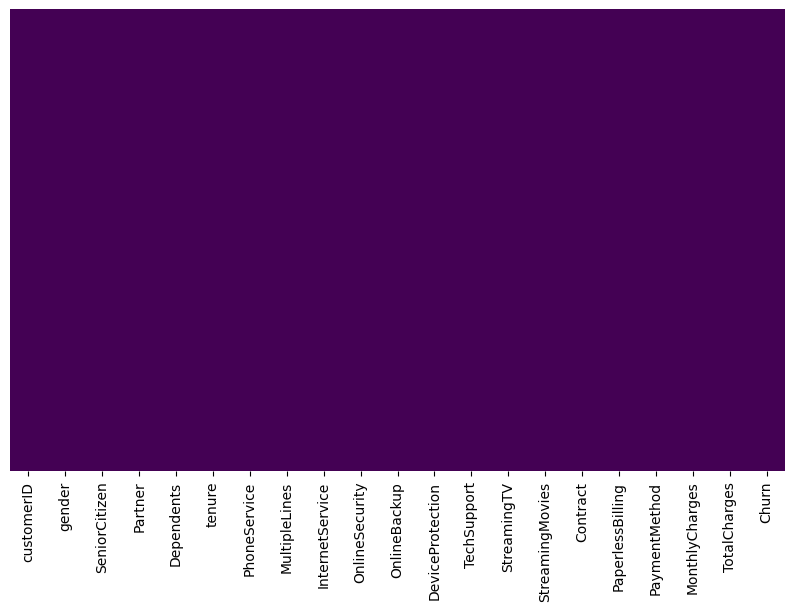

In [7]:
# Checking the missing values
plt.figure(figsize=(10,6))
sns.heatmap(tele_df.isnull(), yticklabels=False, cbar=False, cmap='viridis')

In [8]:
tele_df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [9]:
# Checking the duplicate rows
tele_df.duplicated().sum()

np.int64(0)

In [10]:
# Checking the Churn column value counts
tele_df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [11]:
# Converting in percentage
tele_df['Churn'].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

# TASK #3: DATA CLEANING

In [12]:
# Converting the TotalCharges column to numeric, coercing errors to NaN
tele_df['TotalCharges'] = pd.to_numeric(tele_df['TotalCharges'], errors='coerce')

In [13]:
# checking the missing values again after conversion
tele_df['TotalCharges'].isnull().sum()

np.int64(11)

In [14]:
# droping the CustomerID column as it is not useful for prediction
tele_df.drop(columns='customerID', axis=1, inplace=True)

In [15]:
# Converting the Churn column to binary values (Yes=1, No=0)
tele_df['Churn'] = tele_df['Churn'].map({'Yes': 1, 'No': 0})

In [16]:
tele_df['Churn'].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

# TASK #4: EXPLORATORY DATA ANALYSIS

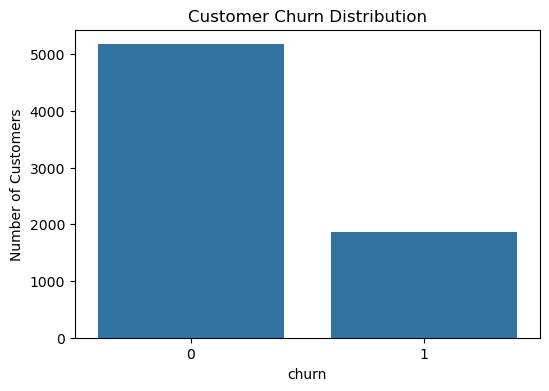

In [17]:
# Plotting the distribution of the target variable
plt.figure(figsize=(6,4))
sns.countplot(x='Churn', data=tele_df)

plt.title('Customer Churn Distribution')
plt.xlabel('churn')
plt.ylabel('Number of Customers')
plt.show()

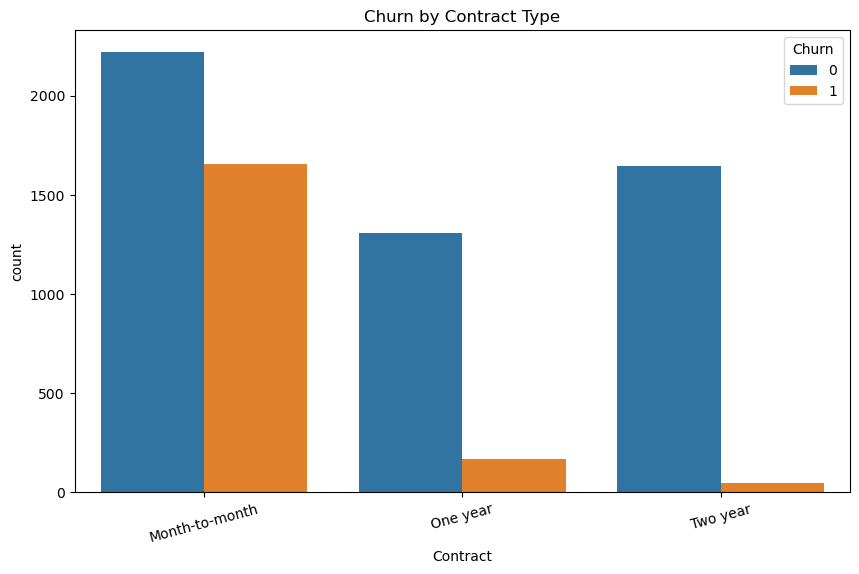

In [18]:
# Creating a count plot showing the number of customers
# for each contract type, separated by Churn

plt.figure(figsize=(10, 6))

sns.countplot(x='Contract', hue='Churn', data=tele_df)
plt.title('Churn by Contract Type')
plt.xticks(rotation=15)
plt.show()

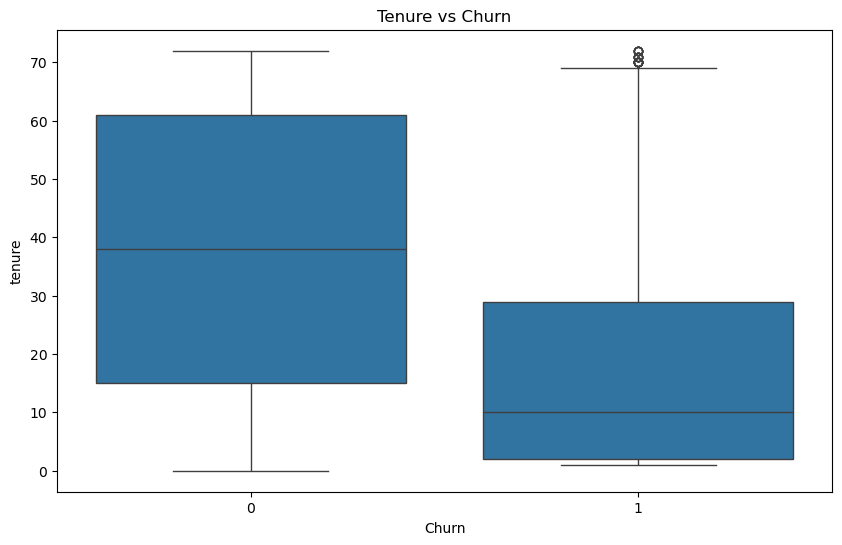

In [19]:
# Creating a boxplot to compare tenure for churned and non-churned customers

plt.figure(figsize=(10, 6))

sns.boxplot(x='Churn', y='tenure', data=tele_df)
plt.title('Tenure vs Churn')
plt.show()

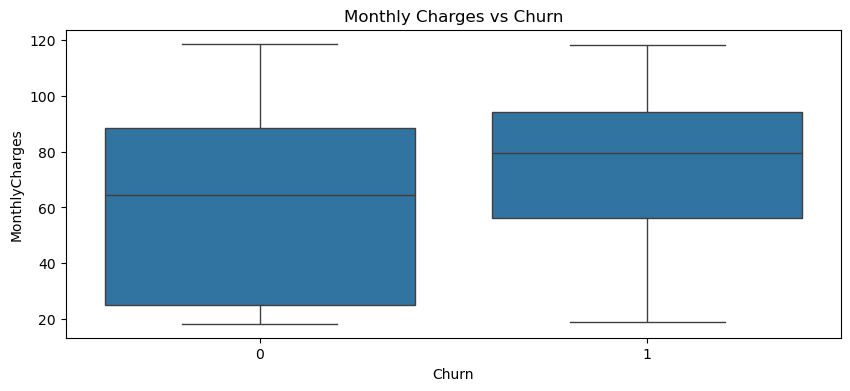

In [20]:
# Creating a boxplot to compare monthly charges
# between churned and non-churned customers

plt.figure(figsize=(10, 4))

sns.boxplot(x='Churn', y='MonthlyCharges', data=tele_df)
plt.title('Monthly Charges vs Churn')
plt.show()

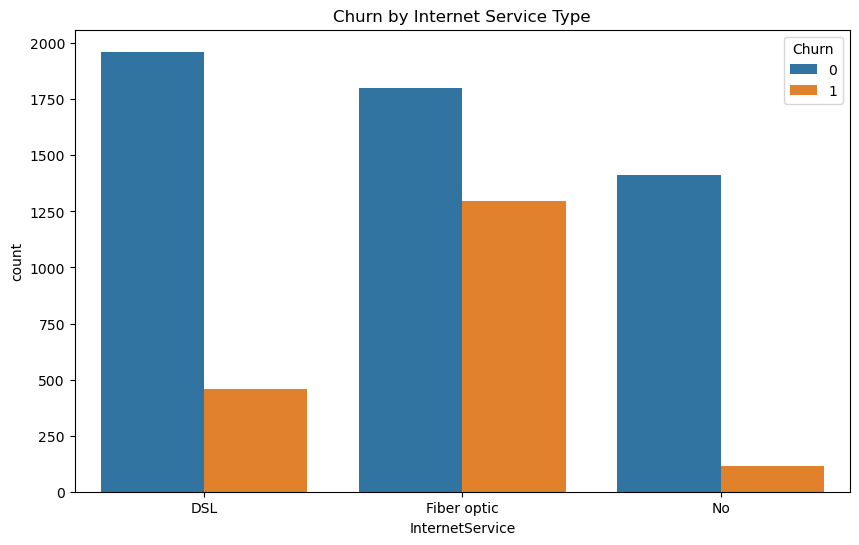

In [21]:
# Creating a count plot showing the number of customers
# for each Internet type, separated by Churn

plt.figure(figsize=(10, 6))

sns.countplot(x='InternetService', hue='Churn', data=tele_df)
plt.title('Churn by Internet Service Type')
plt.show()

In [22]:
# Separating the features and target variable
X = tele_df.drop(columns=['Churn'], axis=1)
y = tele_df['Churn']

In [23]:
X.shape

(7043, 19)

In [24]:
y.shape

(7043,)

In [25]:
# identifying categorical and numerical columns

numerical_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

print('Numerical Features:', numerical_features)
print('Categorical Features:', categorical_features)

Numerical Features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical Features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


# TASK #5: DATA SPLITING AND BUILDING PREPROCESSING PIPELINE 

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [32]:
# Creating a pipeline for preprocessing numerical features

numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
    ])

In [33]:
# Creating a pipeline for preprocessing categorical features

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore' # Ignore new categories during prediction
                              , sparse_output=False )) # Return the output as a regular array
])

In [34]:
# Creating a ColumnTransformer to apply different preprocessing to numerical and categorical features

preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_features), 
    ('cat', categorical_pipeline, categorical_features) 
])

# TASK #6: TRAIN AND EVALUATE ON LOGISTIC REGRESSION

In [35]:
logistic_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])

In [36]:
logistic_pipeline.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [37]:
lr_pred = logistic_pipeline.predict(X_test)

lr_prob = logistic_pipeline.predict_proba(X_test)[:, 1]

In [38]:
print(classification_report(y_test, lr_pred))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [39]:
roc_auc = roc_auc_score(y_test, lr_prob)